<a href="https://colab.research.google.com/github/nachopedretti/diploup2026-TP3/blob/main/TP3_01_Discovery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP3 — Discovery: análisis de tweets

In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import drive
import subprocess

carpeta_proyecto = Path("/content/diploup2026-TP3")
if not (carpeta_proyecto / ".git").exists():
    subprocess.run(["git", "clone", "https://github.com/nachopedretti/diploup2026-TP3.git", str(carpeta_proyecto)], check=True)

carpeta_muestras = carpeta_proyecto / "datos" / "muestras"
carpeta_originales = carpeta_proyecto / "datos" / "originales"
carpeta_procesados = carpeta_proyecto / "datos" / "procesados"
carpeta_resultados = carpeta_proyecto / "datos" / "resultados"

drive.mount("/content/drive")
carpeta_drive = Path("/content/drive/MyDrive/diploup2026-TP3")
carpeta_originales_drive = carpeta_drive / "datos" / "originales"
carpeta_resultados_drive = carpeta_drive / "datos" / "resultados"
carpeta_procesados_drive = carpeta_drive / "datos" / "procesados"
for carpeta in [carpeta_originales_drive, carpeta_resultados_drive, carpeta_procesados_drive]:
    carpeta.mkdir(parents=True, exist_ok=True)

ruta_muestra = carpeta_muestras / "tweets_muestra_100k.csv"
ruta_original = carpeta_originales_drive / "training.1600000.processed.noemoticon.csv"
print("Repositorio:", carpeta_proyecto)
print("Muestra existente:", ruta_muestra.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Repositorio: /content/diploup2026-TP3
Muestra existente: True


In [74]:
# Configuración del Discovery
USAR_MUESTRA = True
ruta_original = Path("/content/drive/MyDrive/DiploIA/TP3/trainingandtestdata/training.1600000.processed.noemoticon.csv")

if USAR_MUESTRA:
    ruta_datos = "datos/muestras/tweets_muestra_100k.csv"
else:
    ruta_datos = "datos/originales/tweets_entrenamiento.csv"


In [75]:
columnas = ["sentimiento", "ID", "fecha", "consulta", "usuario", "texto"]

def normalizar_columnas(datos):
    return datos.rename(columns={"id": "ID"})

if USAR_MUESTRA:
    if not ruta_muestra.exists():
        raise FileNotFoundError(f"No se encontró la muestra: {ruta_muestra}")

    df_entrenamiento = pd.read_csv(ruta_muestra, encoding="utf-8")
    print("Muestra cargada desde GitHub")

else:
    if not ruta_original.exists():
        raise FileNotFoundError(f"No se encontró el dataset original: {ruta_original}")

    df_entrenamiento = pd.read_csv(
        ruta_original,
        encoding="latin-1",
        header=None,
        names=columnas)
    print("Dataset completo cargado desde Google Drive")

df_entrenamiento = normalizar_columnas(df_entrenamiento)

print("Dimensiones:", df_entrenamiento.shape)
print("Columnas:", df_entrenamiento.columns.tolist())

Muestra cargada desde GitHub
Dimensiones: (100000, 6)
Columnas: ['sentimiento', 'ID', 'fecha', 'consulta', 'usuario', 'texto']


In [76]:
import nltk
from nltk.tokenize import word_tokenize

# Descargar los recursos necesarios para tokenizar
nltk.download("punkt")
nltk.download("punkt_tab")

# Extraer palabras utilizando NLTK
def extraer_palabras(texto):

    # Tokenizar y convertir a minúsculas
    tokens = word_tokenize(texto.lower())

    # Conservar los tokens que comienzan con una letra
    palabras = [
        token for token in tokens
        if token and token[0].isalpha()]

    return palabras

# Comprobar el funcionamiento
texto_ejemplo = "I don't like this, but I love music!"

print(extraer_palabras(texto_ejemplo))


['i', 'do', "n't", 'like', 'this', 'but', 'i', 'love', 'music']


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [77]:
from collections import Counter

# Función para obtener combinaciones de dos palabras
def extraer_bigramas(texto):
    palabras = extraer_palabras(texto)

    return [
        (palabras[i], palabras[i + 1])
        for i in range(len(palabras) - 1)]

# Reunir los bigramas de todos los tweets
bigramas_tweets = []

for texto in df_entrenamiento["texto"]:
    bigramas_tweets.extend(extraer_bigramas(texto))

# Contar las combinaciones más frecuentes
frecuencia_bigramas = Counter(bigramas_tweets)

# Crear tabla con los 20 bigramas más frecuentes
tabla_bigramas = pd.DataFrame(
    [
        (" ".join(bigrama), frecuencia)
        for bigrama, frecuencia
        in frecuencia_bigramas.most_common(20)
    ],
    columns=["bigrama", "frecuencia"])

print("20 BIGRAMAS MÁS FRECUENTES")
display(tabla_bigramas)


20 BIGRAMAS MÁS FRECUENTES


,bigrama,frecuencia
0,i have,3201
1,do n't,3108
2,ca n't,2901
3,in the,2836
4,going to,2707
5,and i,2272
6,i am,2227
7,but i,2209
8,for the,2194
9,i love,1985


In [78]:
# Verificar valores faltantes
print("Valores faltantes por variable:")
print(df_entrenamiento.isnull().sum())

# Verificar registros duplicados
print("\nRegistros completamente duplicados:")
print(df_entrenamiento.duplicated().sum())

# Verificar identificadores duplicados
print("\nIdentificadores duplicados:")
print(df_entrenamiento["ID"].duplicated().sum())

# Verificar textos duplicados
print("\nTextos duplicados:")
print(df_entrenamiento["texto"].duplicated().sum())

# Verificar textos vacíos
print("\nTextos vacíos:")
print(df_entrenamiento["texto"].fillna("").str.strip().eq("").sum())

Valores faltantes por variable:
sentimiento    0
ID             0
fecha          0
consulta       0
usuario        0
texto          0
dtype: int64

Registros completamente duplicados:
0

Identificadores duplicados:
7

Textos duplicados:
318

Textos vacíos:
0


### Análisis de calidad de datos

Se evaluó la calidad del conjunto de datos para identificar valores faltantes, registros duplicados, identificadores repetidos y textos vacíos.

No se encontraron valores faltantes, registros completamente duplicados ni textos vacíos.

Se detectaron identificadores y textos repetidos, cuya cantidad varía según el conjunto de datos utilizado.

Estos casos requieren un análisis adicional para identificar posibles contradicciones en las etiquetas de sentimiento y determinar su tratamiento durante el preprocesamiento.

In [79]:
# Seleccionar registros con identificadores repetidos
identificadores_duplicados = df_entrenamiento[
    df_entrenamiento.duplicated(subset=["ID"], keep=False)]
# Analizar las diferencias entre registros
revision_duplicados = (
    identificadores_duplicados
    .groupby("ID")
    .agg(cantidad_registros=("ID", "size"),
        usuarios_diferentes=("usuario", "nunique"),
        textos_diferentes=("texto", "nunique"),
        sentimientos_diferentes=("sentimiento", "nunique"),
        fechas_diferentes=("fecha", "nunique")))
display(revision_duplicados)

,cantidad_registros,usuarios_diferentes,textos_diferentes,sentimientos_diferentes,fechas_diferentes
ID,,,,,
1685502710,2,1,1,2,1
1834777946,2,1,1,2,1
1881916233,2,1,1,2,1
1981071206,2,1,1,2,1
1984396408,2,1,1,2,1
2052948151,2,1,1,2,1
2189659721,2,1,1,2,1


### Análisis de identificadores duplicados

Se identificaron registros que comparten un mismo ID.

Para analizar estos casos, se compararon los usuarios, textos, fechas y etiquetas de sentimiento asociados a cada identificador repetido.

Este análisis permite detectar posibles inconsistencias en los datos, especialmente cuando un mismo identificador presenta diferentes etiquetas de sentimiento.

Estas situaciones deberán considerarse durante el preprocesamiento para evitar introducir información contradictoria en el entrenamiento de los modelos.

# Identificar textos con sentimientos contradictorios


In [80]:
sentimientos_por_texto = (df_entrenamiento
    .groupby("texto")["sentimiento"]
    .nunique())

textos_contradictorios = sentimientos_por_texto[
    sentimientos_por_texto > 1]

# Obtener los registros involucrados
registros_contradictorios = df_entrenamiento[
    df_entrenamiento["texto"].isin(textos_contradictorios.index)].copy()

# Crear una columna descriptiva
registros_contradictorios["clasificacion"] = (
    registros_contradictorios["sentimiento"].map({
        0: "Negativo",
        4: "Positivo"}))

# Ordenar para mostrar juntos los textos iguales
tabla_contradicciones = (
    registros_contradictorios[
        ["texto", "ID", "usuario", "clasificacion"]
]
    .sort_values(["texto", "clasificacion"])
    .reset_index(drop=True))

# Mostrar resumen
print("Textos con sentimientos contradictorios:",
      len(textos_contradictorios))

print("Registros involucrados:",
      len(registros_contradictorios))

# Mostrar los primeros 20 registros en una tabla
display(
    tabla_contradicciones.head(20).style
    .set_properties(**{
        "text-align": "left",
        "white-space": "normal"
    }))

Textos con sentimientos contradictorios: 22
Registros involucrados: 54


,texto,ID,usuario,clasificacion
0,#jaljeera can't beat #followfriday More People know Friday than Jaljeera,1881916233,theSuda,Negativo
1,#jaljeera can't beat #followfriday More People know Friday than Jaljeera,1881916233,theSuda,Positivo
2,@WH1SKS sorry i'm in bed already. I don't sleep in clothes.... And i'm can't really take pictures of invisi-knickers,1984396408,tyefighter,Negativo
3,@WH1SKS sorry i'm in bed already. I don't sleep in clothes.... And i'm can't really take pictures of invisi-knickers,1984396408,tyefighter,Positivo
4,@alicebates LOLO Awwww thats so cute. I want a tortoise,1981071206,smileymango,Negativo
5,@alicebates LOLO Awwww thats so cute. I want a tortoise,1981071206,smileymango,Positivo
6,@jolliehaybowes You looked really pretty at soap awards! And your scene was only one tht made everyone laugh! You should have won x,1834777946,Natalie__xo,Negativo
7,@jolliehaybowes You looked really pretty at soap awards! And your scene was only one tht made everyone laugh! You should have won x,1834777946,Natalie__xo,Positivo
8,@leolodreamland shame about the weather today tho .. v.v. soggy!,2052948151,carolinekerrang,Negativo
9,@leolodreamland shame about the weather today tho .. v.v. soggy!,2052948151,carolinekerrang,Positivo


# Resumir los textos contradictorios según sus identificadores


In [81]:
resumen_textos = (registros_contradictorios
    .groupby("texto")
    .agg(
        registros=("ID", "size"),
        identificadores_diferentes=("ID", "nunique"),
        usuarios_diferentes=("usuario", "nunique"),
        sentimientos_diferentes=("sentimiento", "nunique"))
    .reset_index())
# Identificar si existe algún ID repetido dentro de cada texto
resumen_textos["ID_duplicado"] = (
    resumen_textos["registros"]
    > resumen_textos["identificadores_diferentes"])
# Mostrar resumen general
print("Textos contradictorios con ID duplicados:",
      resumen_textos["ID_duplicado"].sum())

print("Textos contradictorios sin ID duplicados:",
      (~resumen_textos["ID_duplicado"]).sum())
# Mostrar tabla completa
display(
    resumen_textos.style
    .set_properties(**{
        "text-align": "left",
        "white-space": "normal"}))

Textos contradictorios con ID duplicados: 7
Textos contradictorios sin ID duplicados: 15


,texto,registros,identificadores_diferentes,usuarios_diferentes,sentimientos_diferentes,ID_duplicado
0,#jaljeera can't beat #followfriday More People know Friday than Jaljeera,2,1,1,2,True
1,@WH1SKS sorry i'm in bed already. I don't sleep in clothes.... And i'm can't really take pictures of invisi-knickers,2,1,1,2,True
2,@alicebates LOLO Awwww thats so cute. I want a tortoise,2,1,1,2,True
3,@jolliehaybowes You looked really pretty at soap awards! And your scene was only one tht made everyone laugh! You should have won x,2,1,1,2,True
4,@leolodreamland shame about the weather today tho .. v.v. soggy!,2,1,1,2,True
5,@tommcfly,2,2,2,2,False
6,At work,4,4,4,2,False
7,Back to work,2,2,2,2,False
8,Back to work.,2,2,2,2,False
9,I don't know,2,2,2,2,False


### Análisis de textos con sentimientos contradictorios

Se identificaron textos que aparecen más de una vez con diferentes etiquetas de sentimiento.

Para analizar estas contradicciones, se compararon los identificadores y usuarios asociados a cada texto.

Se distinguieron casos en los que un mismo texto comparte identificador y casos en los que aparece con identificadores diferentes.

Estas inconsistencias pueden introducir ambigüedad durante el entrenamiento, ya que un mismo contenido textual puede estar asociado tanto a un sentimiento positivo como negativo.

Por este motivo, será necesario evaluar su tratamiento durante el preprocesamiento, antes de entrenar los modelos de clasificación.

##Análisis de longitud de los tweets

In [82]:

# Calcular la cantidad de caracteres de cada tweet
df_entrenamiento["cantidad_caracteres"] = (
    df_entrenamiento["texto"].str.len())

# Calcular la cantidad de palabras de cada tweet
df_entrenamiento["cantidad_palabras"] = (
    df_entrenamiento["texto"].str.split().str.len())

# Obtener estadísticas descriptivas generales
resumen_longitud = df_entrenamiento[
    ["cantidad_caracteres", "cantidad_palabras"]].describe().round(2)

print("ESTADÍSTICAS GENERALES DE LONGITUD")
display(resumen_longitud)

# Comparar la longitud según el sentimiento
resumen_por_sentimiento = (
    df_entrenamiento
    .groupby("sentimiento")[
        ["cantidad_caracteres", "cantidad_palabras"]
    ]
    .agg(["mean", "median", "min", "max"])
    .round(2))

# Reemplazar códigos por nombres descriptivos
resumen_por_sentimiento.index = (
    resumen_por_sentimiento.index.map({
        0: "Negativo",
        4: "Positivo"
    }))

print("\nLONGITUD SEGÚN SENTIMIENTO")
display(resumen_por_sentimiento)


ESTADÍSTICAS GENERALES DE LONGITUD


,cantidad_caracteres,cantidad_palabras
count,100000.00,100000.00
mean,74.08,13.18
std,36.45,6.96
min,6.00,1.00
25%,44.00,7.00
50%,69.00,12.00
75%,104.00,19.00
max,245.00,44.00



LONGITUD SEGÚN SENTIMIENTO


cantidad_caracteres                 cantidad_palabras             \
                           mean median min  max              mean median min   
sentimiento                                                                    
Negativo                  74.19   69.0   6  211             13.57   13.0   1   
Positivo                  73.96   69.0   7  245             12.79   12.0   1   

                 
            max  
sentimiento      
Negativo     44  
Positivo     34

**No hay diferencia relevante entre los tweets positivos y negativos en relacion de cantidad de caracteres**

#Histograma de la cantidad de palabras

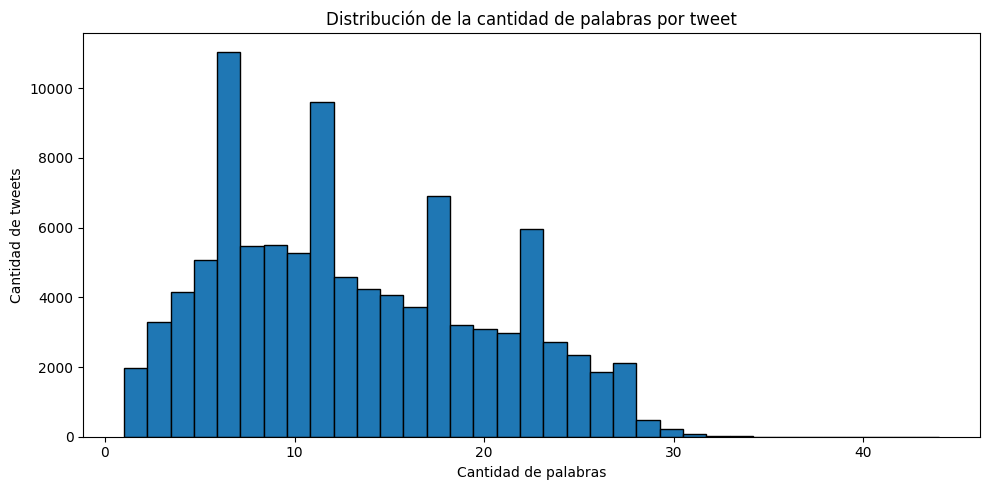

In [83]:

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))

plt.hist(
    df_entrenamiento["cantidad_palabras"],
    bins=35,
    edgecolor="black")

plt.title("Distribución de la cantidad de palabras por tweet")
plt.xlabel("Cantidad de palabras")
plt.ylabel("Cantidad de tweets")

plt.tight_layout()
plt.show()

- Predominan los mensajes cortos
- Poca frecuencia de tweets largos
-

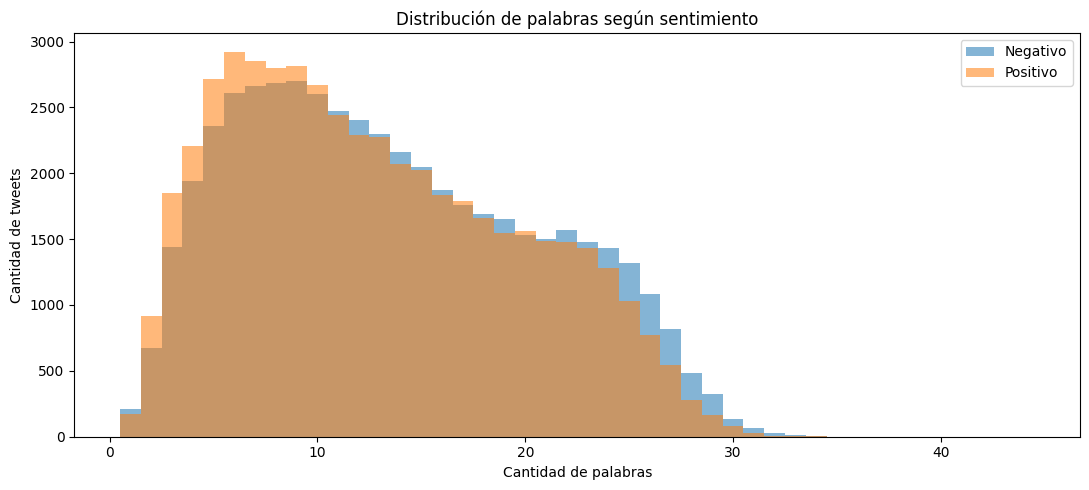

In [84]:
import matplotlib.pyplot as plt
import numpy as np

# Separar la cantidad de palabras por sentimiento
palabras_negativas = df_entrenamiento.loc[
    df_entrenamiento["sentimiento"] == 0,
    "cantidad_palabras"]

palabras_positivas = df_entrenamiento.loc[
    df_entrenamiento["sentimiento"] == 4,
    "cantidad_palabras"]

# Usar los mismos intervalos para ambas distribuciones
intervalos = np.arange(0.5, 45.5, 1)

plt.figure(figsize=(11, 5))

plt.hist(
    palabras_negativas,
    bins=intervalos,
    alpha=0.55,
    label="Negativo")

plt.hist(
    palabras_positivas,
    bins=intervalos,
    alpha=0.55,
    label="Positivo")

plt.title("Distribución de palabras según sentimiento")
plt.xlabel("Cantidad de palabras")
plt.ylabel("Cantidad de tweets")
plt.legend()
plt.tight_layout()
plt.show()


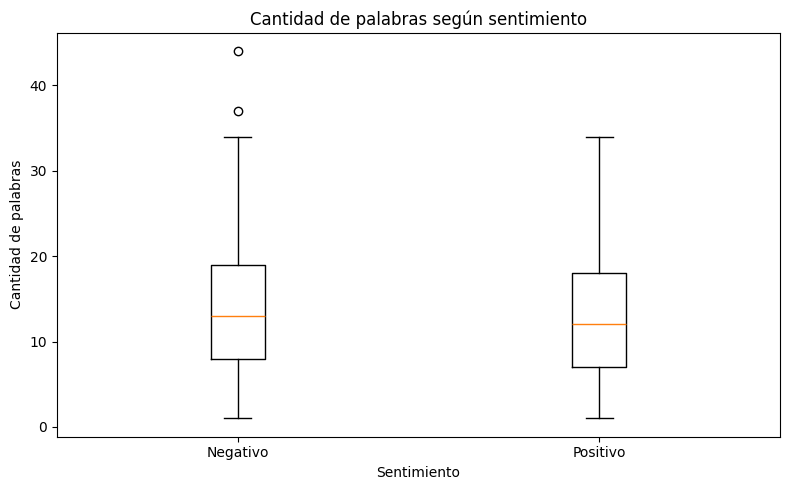

In [85]:

import matplotlib.pyplot as plt

# Separar la longitud de los tweets según sentimiento
palabras_negativas = df_entrenamiento.loc[
    df_entrenamiento["sentimiento"] == 0,
    "cantidad_palabras"
]

palabras_positivas = df_entrenamiento.loc[
    df_entrenamiento["sentimiento"] == 4,
    "cantidad_palabras"
]

# Comparar ambas distribuciones mediante un boxplot
plt.figure(figsize=(8, 5))

plt.boxplot(
    [palabras_negativas, palabras_positivas],
    tick_labels=["Negativo", "Positivo"]
)

plt.title("Cantidad de palabras según sentimiento")
plt.xlabel("Sentimiento")
plt.ylabel("Cantidad de palabras")
plt.tight_layout()
plt.show()


#tweets más cortos y más largos

In [86]:

# Seleccionar los tweets más cortos y más largos
columnas = [
    "ID", "texto", "sentimiento",
    "cantidad_caracteres", "cantidad_palabras"]

tweets_cortos = (
    df_entrenamiento[columnas]
    .sort_values(["cantidad_palabras", "cantidad_caracteres"])
    .head(10)
    .copy())

tweets_largos = (
    df_entrenamiento[columnas]
    .sort_values("cantidad_palabras", ascending=False)
    .head(10)
    .copy())

# Mostrar etiquetas descriptivas
for tabla in [tweets_cortos, tweets_largos]:
    tabla["sentimiento"] = tabla["sentimiento"].map({
        0: "Negativo",
        4: "Positivo"
    })

print("TABLA 1 - TWEETS MÁS CORTOS")
display(tweets_cortos)

print("\nTABLA 2 - TWEETS CON MÁS PALABRAS")
display(tweets_largos)


TABLA 1 - TWEETS MÁS CORTOS


,ID,texto,sentimiento,cantidad_caracteres,cantidad_palabras
57258,1468771833,just,Negativo,6,1
48090,1834334814,Monday,Negativo,7,1
91781,2189441231,online,Positivo,7,1
4585,2264334946,Nothing,Negativo,8,1
4723,1752847331,freedom,Positivo,8,1
6678,2298802863,@tcms12,Negativo,8,1
6703,1687248037,Houston,Positivo,8,1
8540,2055560951,cramps!,Negativo,8,1
12219,2255599612,Packing,Negativo,8,1
16977,2056224555,Anytime,Positivo,8,1



TABLA 2 - TWEETS CON MÁS PALABRAS


,ID,texto,sentimiento,cantidad_caracteres,cantidad_palabras
53412,2174350763,Is the saddest zornes ever thanks to the magic...,Negativo,137,44
17319,2194315263,@LaurenConrad â â â â¥ â¥ â¥ L.A. Candy...,Negativo,162,37
47579,2243245055,Today have been a slow day so there's not much...,Negativo,141,34
52185,2190160455,my 51th or now 52 or or or or or or or or or o...,Positivo,132,34
67843,2206850784,ChÆ°a ká»p thá» máº¡nh ÄÃ£ láº¡i nÃ­n thá»...,Negativo,188,34
75362,2236241178,Ugh I have so mutch 2 edit and I have no time ...,Negativo,136,34
74047,1696135992,hahas . dam tried . just nw got exam . don kno...,Positivo,138,34
4232,1573908174,@fafinettex3 n my bday on may 3 n my dad wnt b...,Negativo,137,34
41976,2182889311,and b4 i go he tell me im the best then he kis...,Positivo,139,34
88887,1833849391,argh! I hate IE &amp; know it always freezes ...,Negativo,149,33



###Análisis de tweets extremos

Se revisaron los diez tweets con menor cantidad de palabras
y los diez con mayor cantidad de palabras.

Entre los mensajes más cortos se identificaron publicaciones
de una sola palabra, menciones a usuarios y expresiones
que pueden resultar ambiguas sin información contextual.

Entre los mensajes más largos se observaron repeticiones
de palabras, abreviaturas, menciones, entidades HTML y
caracteres aparentemente mal codificados.

También se encontraron textos que superan los 140
caracteres, situación que requiere una revisión adicional.

**Conclusión:** el análisis evidencia características
propias del lenguaje informal de redes sociales y posibles
problemas de representación del texto.

Estos hallazgos serán considerados durante el
preprocesamiento, evitando eliminar información que
pueda resultar relevante para el análisis de sentimientos.


In [87]:
# Detectar elementos presentes en los tweets originales
df_entrenamiento["tiene_mencion"] = (
    df_entrenamiento["texto"].str.contains(
        r"@\w+", regex=True))

df_entrenamiento["tiene_hashtag"] = (
    df_entrenamiento["texto"].str.contains(
        r"#\w+", regex=True))

df_entrenamiento["tiene_url"] = (
    df_entrenamiento["texto"].str.contains(
        r"https?://|www\.", regex=True, case=False))

df_entrenamiento["tiene_caracteres_especiales"] = (
    df_entrenamiento["texto"].str.contains(
        r"&(?:[A-Za-z]+|#\d+|#x[0-9A-Fa-f]+);",
        regex=True))

# Resumir cantidad y porcentaje de tweets
columnas_caracteristicas = [
    "tiene_mencion",
    "tiene_hashtag",
    "tiene_url",
    "tiene_caracteres_especiales"]

resumen_caracteristicas = (
    df_entrenamiento[columnas_caracteristicas]
    .sum()
    .to_frame(name="cantidad_tweets"))

resumen_caracteristicas["porcentaje"] = (
    resumen_caracteristicas["cantidad_tweets"]
    / len(df_entrenamiento) * 100).round(2)

display(resumen_caracteristicas)


,cantidad_tweets,porcentaje
tiene_mencion,46264,46.26
tiene_hashtag,2202,2.20
tiene_url,4798,4.80
tiene_caracteres_especiales,5937,5.94


Calcular el porcentaje de cada característica según sentimiento

In [88]:
caracteristicas_por_sentimiento = (
    df_entrenamiento
    .groupby("sentimiento")[columnas_caracteristicas]
    .mean()
    .mul(100)
    .round(2))

Reemplazar los códigos por etiquetas descriptivas


In [89]:
caracteristicas_por_sentimiento.index = (
    caracteristicas_por_sentimiento.index.map({
        0: "Negativo",
        4: "Positivo"}))

Mejorar los nombres de las columnas

In [90]:
caracteristicas_por_sentimiento = (
    caracteristicas_por_sentimiento.rename(columns={
        "tiene_mencion": "Menciones (%)",
        "tiene_hashtag": "Hashtags (%)",
        "tiene_url": "URLs (%)",
        "tiene_caracteres_especiales": "Caracteres Especiales (%)"}))

print("CARACTERÍSTICAS DEL TEXTO SEGÚN SENTIMIENTO")
display(caracteristicas_por_sentimiento)

CARACTERÍSTICAS DEL TEXTO SEGÚN SENTIMIENTO


,Menciones (%),Hashtags (%),URLs (%),Caracteres Especiales (%)
sentimiento,,,,
Negativo,37.66,1.93,3.13,4.95
Positivo,54.87,2.48,6.47,6.93


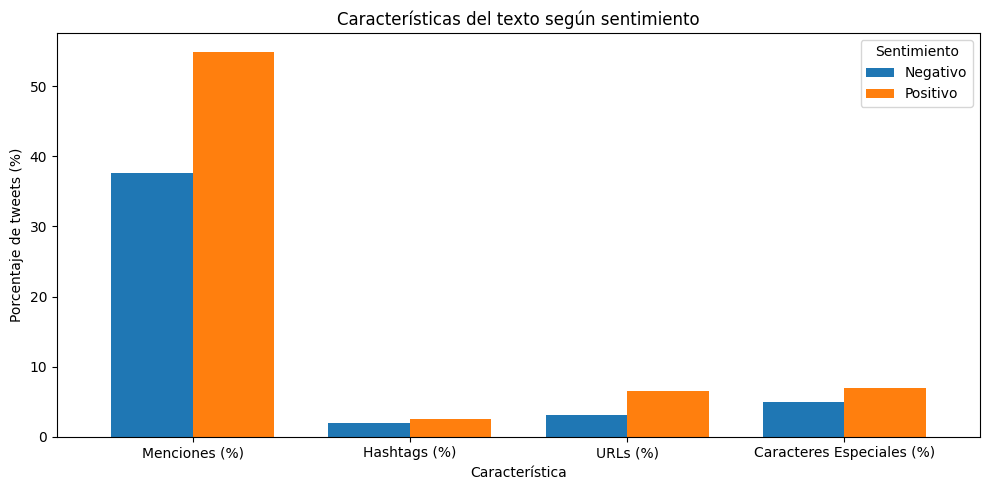

In [91]:
import matplotlib.pyplot as plt

# Preparar la tabla para el gráfico
datos_grafico = caracteristicas_por_sentimiento.T

# Gráfico de barras agrupadas
ax = datos_grafico.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75)

plt.title("Características del texto según sentimiento")
plt.xlabel("Característica")
plt.ylabel("Porcentaje de tweets (%)")
plt.xticks(rotation=0)
plt.legend(title="Sentimiento")
plt.tight_layout()
plt.show()


las menciones presentan la mayor diferencia
entre ambas categorías. Durante el preprocesamiento
se evaluará cómo tratar las menciones y URLs, conservar
la información relevante de los hashtags y convertir
los códigos HTML a sus signos y caracteres originales.

### Selección del conjunto de datos

El conjunto original Sentiment140 contiene 1.600.000 tweets clasificados según su sentimiento.

Debido al volumen de información, se dispone también de una muestra aleatoria de 100.000 tweets, equilibrada entre las categorías positiva y negativa, generada utilizando una semilla aleatoria de 42 para facilitar la reproducibilidad.

La muestra permite realizar análisis y pruebas con menor tiempo de procesamiento, mientras que el conjunto completo permite trabajar con la totalidad de los registros disponibles.

El notebook permite seleccionar cualquiera de las dos alternativas mediante la variable `USAR_MUESTRA`, sin necesidad de modificar el resto del análisis.

##Visualizar las distribuciones

### Estructura del conjunto de datos

Se analiza la estructura del conjunto de datos seleccionado, identificando la cantidad de registros, las variables disponibles y sus tipos de datos.

Esta revisión permite verificar que la información se haya cargado correctamente y conocer las características generales del dataset antes de continuar con el análisis exploratorio.

La cantidad de registros depende de la configuración de `USAR_MUESTRA`, que permite trabajar con una muestra de 100.000 tweets o con el conjunto completo de 1.600.000 registros.

In [92]:
# Dimensiones de la muestra
print("Dimensiones del conjunto de datos:")
print(df_entrenamiento.shape)

# Nombres de las variables
print("\nVariables disponibles:")
print(df_entrenamiento.columns.tolist())

# Tipos de datos
print("\nInformación general:")
df_entrenamiento.info()

# Primeros registros
print("\nPrimeros cinco registros:")
display(df_entrenamiento.head())

Dimensiones del conjunto de datos:
(100000, 12)

Variables disponibles:
['sentimiento', 'ID', 'fecha', 'consulta', 'usuario', 'texto', 'cantidad_caracteres', 'cantidad_palabras', 'tiene_mencion', 'tiene_hashtag', 'tiene_url', 'tiene_caracteres_especiales']

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 12 columns):
 #   Column                       Non-Null Count   Dtype 
---  ------                       --------------   ----- 
 0   sentimiento                  100000 non-null  int64 
 1   ID                           100000 non-null  int64 
 2   fecha                        100000 non-null  object
 3   consulta                     100000 non-null  object
 4   usuario                      100000 non-null  object
 5   texto                        100000 non-null  object
 6   cantidad_caracteres          100000 non-null  int64 
 7   cantidad_palabras            100000 non-null  int64 
 8   tiene_mencion             

,sentimiento,ID,fecha,consulta,usuario,texto,cantidad_caracteres,cantidad_palabras,tiene_mencion,tiene_hashtag,tiene_url,tiene_caracteres_especiales
0,4,1964895956,Fri May 29 14:59:19 PDT 2009,NO_QUERY,thomscottart,15th piece for Neuwerld sent and waiting appro...,132,26,False,False,False,False
1,4,1994295873,Mon Jun 01 11:43:00 PDT 2009,NO_QUERY,mohawksteveo,no twat for 2 days! must have gotten my ass ki...,64,13,False,False,False,False
2,0,2192879825,Tue Jun 16 07:41:04 PDT 2009,NO_QUERY,rbarbera,We're getting several confirmations that some ...,139,21,True,False,False,False
3,4,2178789227,Mon Jun 15 08:12:24 PDT 2009,NO_QUERY,xMileyCyrusTeam,Please follow!!,16,2,False,False,False,False
4,4,2016281867,Wed Jun 03 06:30:14 PDT 2009,NO_QUERY,thebudget,getting ready to have coffee with a good friend,48,9,False,False,False,False


###Análisis de usuarios y textos repetidos

In [93]:
# 1. Usuarios que publicaron más de un tweet
tweets_por_usuario = df_entrenamiento.groupby("usuario").size()

print("Cantidad de usuarios únicos:")
print(df_entrenamiento["usuario"].nunique())

print("\nUsuarios que publicaron más de un tweet:")
print((tweets_por_usuario > 1).sum())

print("\nLos 10 usuarios con más tweets:")
display(
    tweets_por_usuario.sort_values(ascending=False).head(10)
)

# 2. Textos publicados por diferentes usuarios
usuarios_por_texto = df_entrenamiento.groupby("texto")["usuario"].nunique()

textos_compartidos = usuarios_por_texto[
    usuarios_por_texto > 1
].sort_values(ascending=False)

print("\nTextos publicados por diferentes usuarios:")
print(len(textos_compartidos))

print("\nLos 10 textos publicados por más usuarios:")
display(textos_compartidos.head(10))

Cantidad de usuarios únicos:
82846

Usuarios que publicaron más de un tweet:
10825

Los 10 usuarios con más tweets:


,0
usuario,
lost_dog,40
webwoke,25
mcraddictal,21
_magic8ball,21
tweetpet,20
VioletsCRUK,17
nuttychris,16
SallytheShizzle,16
linnetwoods,15



Textos publicados por diferentes usuarios:
153

Los 10 textos publicados por más usuarios:


,usuario
texto,
Good morning,8
headache,8
Good morning!,7
Goodnight,7
Headache,6
I miss you,6
at work,6
Good Morning,5
tummy ache,5


### Usuarios y textos repetidos

El análisis permite identificar usuarios que publicaron múltiples tweets y textos compartidos por diferentes usuarios.

Se observa que algunos usuarios tienen una participación considerablemente mayor que otros. También se identifican mensajes breves y expresiones habituales que aparecen publicados por distintos usuarios.

Entre los textos repetidos se encuentran variantes que únicamente difieren en el uso de mayúsculas y minúsculas, lo que evidencia la importancia de considerar la normalización del texto durante el preprocesamiento.

Estos resultados permiten comprender mejor las características del conjunto de datos y anticipar posibles problemas relacionados con la repetición de mensajes durante el entrenamiento y la evaluación de los modelos.

In [94]:
# Obtener las palabras de todos los tweets
palabras_tweets = []

for texto in df_entrenamiento["texto"]:
    palabras_tweets.extend(extraer_palabras(texto))


In [95]:
# Contar la frecuencia de cada palabra
frecuencia_palabras = Counter(palabras_tweets)

In [96]:
# Crear una tabla con las 20 palabras más frecuentes
tabla_palabras_frecuentes = pd.DataFrame(
    frecuencia_palabras.most_common(20),
    columns=["palabra", "frecuencia"])

print("20 PALABRAS MÁS FRECUENTES")
display(tabla_palabras_frecuentes)

20 PALABRAS MÁS FRECUENTES


,palabra,frecuencia
0,i,59763
1,to,34939
2,the,32190
3,a,23615
4,my,19930
5,it,19053
6,and,19039
7,you,18963
8,is,15706
9,for,13353


In [97]:
# Obtener las 20 palabras más frecuentes ya analizadas
palabras_excluidas = [
    palabra for palabra, frecuencia
    in frecuencia_palabras.most_common(20)]

# Obtener las siguientes 20 palabras más frecuentes
tabla_siguientes_palabras = pd.DataFrame(
    frecuencia_palabras.most_common(40)[20:40],
    columns=["palabra", "frecuencia"])

print("PALABRAS MÁS FRECUENTES - POSICIONES 21 A 40")
display(tabla_siguientes_palabras)


PALABRAS MÁS FRECUENTES - POSICIONES 21 A 40


,palabra,frecuencia
0,do,7341
1,with,7216
2,be,7078
3,not,6966
4,at,6943
5,was,6655
6,now,6011
7,this,5991
8,good,5643
9,up,5534


Al excluir las 20 palabras más frecuentes, comienzan
a aparecer términos que pueden aportar información
sobre el sentimiento, como "good" y "like".

También se identifican negaciones como "not" y "no",
que pueden modificar el significado de las expresiones
y deben considerarse durante el preprocesamiento.

Por otra parte, aparecen términos como "quot" y "http",
relacionados con códigos HTML y direcciones web

# Contar palabras por sentimiento


In [98]:
resultados_por_sentimiento = {}
conteos_por_sentimiento = {}

for sentimiento, nombre in [(0, "Negativo"), (4, "Positivo")]:

    # Seleccionar los tweets de cada categoría
    textos = df_entrenamiento.loc[
        df_entrenamiento["sentimiento"] == sentimiento,
        "texto"]

    # Extraer las palabras
    palabras = []

    for texto in textos:
        palabras.extend(extraer_palabras(texto))

    # Guardar el conteo completo para reutilizarlo
    conteos_por_sentimiento[nombre] = Counter(palabras)

    # Excluir las primeras 20 palabras del análisis general
    conteo_filtrado = Counter({
        palabra: frecuencia
        for palabra, frecuencia in conteos_por_sentimiento[nombre].items()
        if palabra not in palabras_excluidas})

    # Obtener las 15 palabras más frecuentes
    resultados_por_sentimiento[nombre] = (
        conteo_filtrado.most_common(15))

# Mostrar las tablas
for nombre, resultados in resultados_por_sentimiento.items():

    print(f"15 PALABRAS MÁS FRECUENTES - {nombre.upper()}")

    tabla = pd.DataFrame(
        resultados,
        columns=["palabra", "frecuencia"])

    display(tabla)


15 PALABRAS MÁS FRECUENTES - NEGATIVO


,palabra,frecuencia
0,not,4802
1,do,4324
2,at,3938
3,was,3801
4,be,3616
5,now,3343
6,no,3323
7,this,3278
8,with,3243
9,up,3038


15 PALABRAS MÁS FRECUENTES - POSITIVO


,palabra,frecuencia
0,with,3973
1,good,3817
2,be,3462
3,love,3028
4,do,3017
5,at,3005
6,http,2985
7,quot,2938
8,are,2860
9,was,2854


In [99]:

# Seleccionar palabras relevantes para comparar
palabras_comparar = [
    "not", "no", "good", "love",
    "like", "work", "day"]

# Reutilizar los conteos calculados por sentimiento
comparacion_palabras = []

for nombre in ["Negativo", "Positivo"]:

    conteo = conteos_por_sentimiento[nombre]

    for palabra in palabras_comparar:
        comparacion_palabras.append({
            "sentimiento": nombre,
            "palabra": palabra,
            "frecuencia": conteo[palabra]})

# Crear tabla comparativa
tabla_comparacion = pd.DataFrame(comparacion_palabras)

tabla_comparacion = tabla_comparacion.pivot(
    index="palabra",
    columns="sentimiento",
    values="frecuencia")

tabla_comparacion = tabla_comparacion[
    ["Negativo", "Positivo"]]

print("COMPARACIÓN DE PALABRAS SEGÚN SENTIMIENTO")
display(tabla_comparacion)


COMPARACIÓN DE PALABRAS SEGÚN SENTIMIENTO


sentimiento,Negativo,Positivo
palabra,,
day,2421,2838
good,1826,3817
like,2524,2361
love,1091,3028
no,3323,1401
not,4802,2164
work,2917,1231


- love y good predominan en los tweets positivos.

- not y no predominan en los negativos.
- work predomina en los negativos, trabajo, abajo

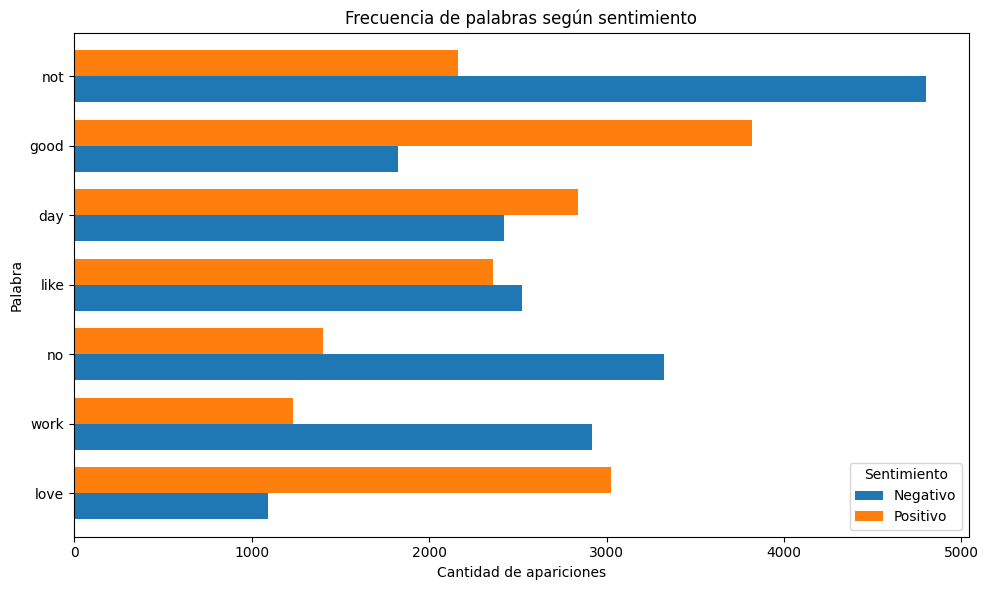

In [100]:

import matplotlib.pyplot as plt

# Ordenar las palabras según su frecuencia total
tabla_grafico = tabla_comparacion.copy()

tabla_grafico["total"] = (
    tabla_grafico["Negativo"] +
    tabla_grafico["Positivo"])

tabla_grafico = tabla_grafico.sort_values("total")

# Graficar las frecuencias por sentimiento
ax = tabla_grafico[
    ["Negativo", "Positivo"]
].plot(
    kind="barh",
    figsize=(10, 6),
    width=0.75)

plt.title("Frecuencia de palabras según sentimiento")
plt.xlabel("Cantidad de apariciones")
plt.ylabel("Palabra")
plt.legend(title="Sentimiento")
plt.tight_layout()
plt.show()


### Análisis de frecuencia de palabras según sentimiento

La comparación de palabras entre tweets positivos y negativos permite identificar diferencias en el vocabulario utilizado.

En los tweets negativos se destacan las negaciones como `not` y `no`, mientras que en los positivos aparecen con mayor frecuencia palabras asociadas con valoraciones favorables, como `good` y `love`.

Estos resultados sugieren que determinadas palabras pueden aportar información relevante para la clasificación de sentimientos.

Durante el preprocesamiento será importante conservar las negaciones, ya que pueden modificar el significado de las expresiones.

# **Análisis de combinaciones de palabras**


# Contar bigramas por sentimiento

In [101]:

resultados_bigramas = {}
conteos_bigramas_por_sentimiento = {}

for sentimiento, nombre in [(0, "Negativo"), (4, "Positivo")]:

    textos = df_entrenamiento.loc[
        df_entrenamiento["sentimiento"] == sentimiento,
        "texto"]

    bigramas = []

    for texto in textos:
        bigramas.extend(extraer_bigramas(texto))

    # Guardar el conteo completo para reutilizarlo
    conteos_bigramas_por_sentimiento[nombre] = Counter(bigramas)

    # Contar las 15 combinaciones más frecuentes
    resultados_bigramas[nombre] = (
        conteos_bigramas_por_sentimiento[nombre].most_common(15))

# Mostrar tablas por categoría
for nombre, resultados in resultados_bigramas.items():

    tabla = pd.DataFrame(
        [
            (" ".join(bigrama), frecuencia)
            for bigrama, frecuencia in resultados
        ],
        columns=["bigrama", "frecuencia"])

    print(f"15 BIGRAMAS MÁS FRECUENTES - {nombre.upper()}")
    display(tabla)


15 BIGRAMAS MÁS FRECUENTES - NEGATIVO


,bigrama,frecuencia
0,i have,2114
1,do n't,2083
2,ca n't,1975
3,in the,1470
4,but i,1436
5,going to,1417
6,and i,1366
7,have to,1317
8,i do,1314
9,to go,1290


15 BIGRAMAS MÁS FRECUENTES - POSITIVO


,bigrama,frecuencia
0,i love,1495
1,for the,1390
2,in the,1366
3,going to,1290
4,i have,1087
5,have a,1068
6,on the,1036
7,do n't,1025
8,i am,1003
9,ca n't,926


In [102]:

# Seleccionar bigramas para comparar
bigramas_comparar = [
    ("i", "miss"),
    ("do", "n't"),
    ("ca", "n't"),
    ("i", "love"),
    ("thank", "you"),
    ("going", "to"),
    ("i", "have")
]

# Reutilizar los conteos por sentimiento
comparacion_bigramas = []

for nombre in ["Negativo", "Positivo"]:

    conteo = conteos_bigramas_por_sentimiento[nombre]

    for bigrama in bigramas_comparar:
        comparacion_bigramas.append({
            "sentimiento": nombre,
            "bigrama": " ".join(bigrama),
            "frecuencia": conteo[bigrama]
        })

# Crear tabla comparativa
tabla_comparacion_bigramas = pd.DataFrame(
    comparacion_bigramas
).pivot(
    index="bigrama",
    columns="sentimiento",
    values="frecuencia"
)

tabla_comparacion_bigramas = tabla_comparacion_bigramas[
    ["Negativo", "Positivo"]
]

print("COMPARACIÓN DE BIGRAMAS SEGÚN SENTIMIENTO")
display(tabla_comparacion_bigramas)


COMPARACIÓN DE BIGRAMAS SEGÚN SENTIMIENTO


sentimiento,Negativo,Positivo
bigrama,,
ca n't,1975,926
do n't,2083,1025
going to,1417,1290
i have,2114,1087
i love,490,1495
i miss,1166,139
thank you,58,820


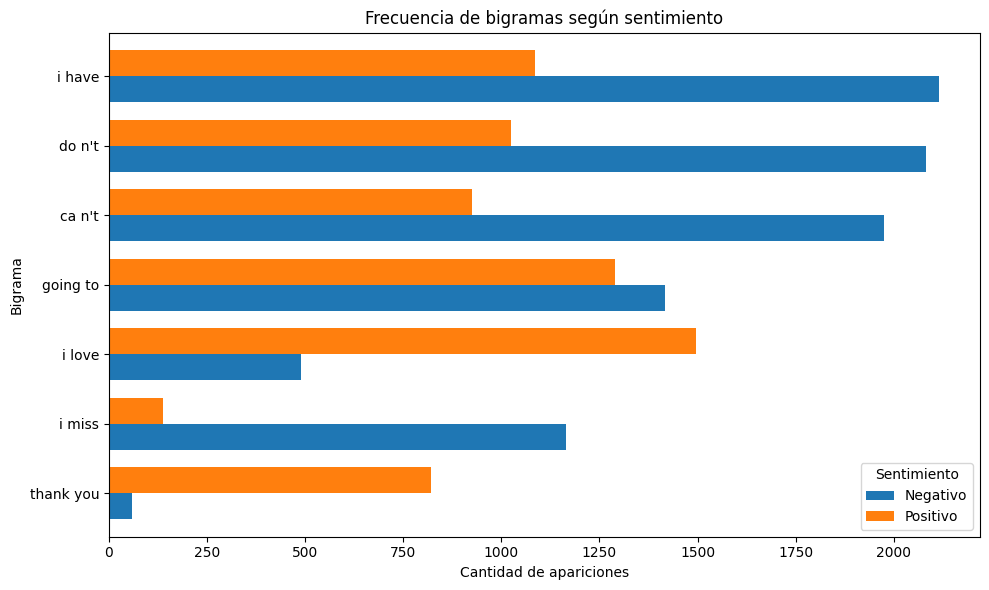

In [103]:

import matplotlib.pyplot as plt

# Ordenar los bigramas por frecuencia total
tabla_grafico_bigramas = tabla_comparacion_bigramas.copy()

tabla_grafico_bigramas["total"] = (
    tabla_grafico_bigramas["Negativo"] +
    tabla_grafico_bigramas["Positivo"])

tabla_grafico_bigramas = (
    tabla_grafico_bigramas.sort_values("total"))

# Comparar las frecuencias por sentimiento
ax = tabla_grafico_bigramas[
    ["Negativo", "Positivo"]
].plot(
    kind="barh",
    figsize=(10, 6),
    width=0.75)

plt.title("Frecuencia de bigramas según sentimiento")
plt.xlabel("Cantidad de apariciones")
plt.ylabel("Bigrama")
plt.legend(title="Sentimiento")
plt.tight_layout()
plt.show()


### Análisis de bigramas por sentimiento

El análisis de bigramas permite identificar combinaciones de palabras que aparecen con diferente frecuencia según el sentimiento de los tweets.

En los tweets negativos se destacan expresiones como `do n't`, `ca n't` e `i miss`, mientras que en los positivos aparecen combinaciones como `i love` y `thank you`.

Estos resultados sugieren que considerar combinaciones de dos palabras puede aportar información adicional respecto del análisis de palabras individuales.

Por este motivo, durante el preprocesamiento será importante conservar las negaciones y evaluar la utilización de bigramas durante la vectorización de los textos.

# Resumen de calidad de datos


In [104]:
resumen_calidad = pd.DataFrame({
    "indicador": ["registros", "usuarios_unicos", "valores_faltantes",
                  "registros_duplicados", "identificadores_duplicados",
                  "textos_duplicados", "textos_vacios"],
    "cantidad": [len(df_entrenamiento), df_entrenamiento["usuario"].nunique(),
                 int(df_entrenamiento.isna().sum().sum()),
                 int(df_entrenamiento.duplicated().sum()),
                 int(df_entrenamiento["ID"].duplicated().sum()),
                 int(df_entrenamiento["texto"].duplicated().sum()),
                 int(df_entrenamiento["texto"].fillna("").str.strip().eq("").sum())]
})
nombre_archivo = f"resumen_calidad_{'100k' if USAR_MUESTRA else '1600k'}.csv"
ruta_resultado = carpeta_resultados_drive / nombre_archivo
resumen_calidad.to_csv(ruta_resultado, index=False)
print("Resultado guardado en Drive:", ruta_resultado)
display(resumen_calidad)

Resultado guardado en Drive: /content/drive/MyDrive/diploup2026-TP3/datos/resultados/resumen_calidad_100k.csv


,indicador,cantidad
0,registros,100000
1,usuarios_unicos,82846
2,valores_faltantes,0
3,registros_duplicados,0
4,identificadores_duplicados,7
5,textos_duplicados,318
6,textos_vacios,0


### Conclusiones del análisis exploratorio

El análisis del dataset Sentiment140 nos permitió conocer mejor los datos e identificar algunas características importantes para la clasificación de sentimientos.

En general, los datos están completos, sin valores nulos ni textos vacíos, aunque encontramos algunos registros y textos repetidos. También identificamos menciones, hashtags, enlaces y caracteres especiales propios de Twitter.

Al comparar los sentimientos, observamos que palabras como `not` y `no` aparecen más en tweets negativos, mientras que `good` y `love` son más frecuentes en los positivos. Algo similar ocurre con los bigramas, donde expresiones como `i miss` e `i love` muestran diferencias entre ambas categorías.

Estos resultados nos sirven para definir cómo vamos a preparar los textos. Será importante revisar los duplicados, tratar los elementos propios de Twitter y conservar las negaciones, ya que pueden cambiar el sentido de una frase.

**Próximos pasos**

En la siguiente notebook vamos a trabajar en el preprocesamiento y la vectorización de los textos, para después entrenar y comparar los modelos de clasificación de sentimientos.